<div style="display: flex; justify-content: space-between; align-items: flex-start; border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: -8px;">
    <div style="width: 50%;">
        <h2>
            <span style="color: #B30033;">▍</span>TRABAJO DE FIN DE MÁSTER
        </h2>
        <h1 style="margin-top: -10px;">
            Creación de un framework para recomendar las personas más adecuadas para trabajar en un determinado proyecto de ingeniería del software
        </h1>
    </div>
    <div style="width: 50%; text-align: right;">
        <div style="display: flex; justify-content: space-between; align-items: flex-start; margin-top: 30px;">
            <div style="width: 20%;"></div>
            <div style="width: 80%; border-left: 2px solid #555555; padding-left: 20px;">
                <div style="margin-bottom: 20px;">
                    <p style="margin: 0; font-size: 1.4em; font-weight: bold;">
                        Profesores
                    </p>
                </div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="display: block; font-size: 1em; color: #D0D0D0;">
                        Aurora Vizcaíno Barcelo
                    </span>
                    <span style="display: block; font-size: 1em; color: #D0D0D0; margin-top: 5px;">
                        Julio Alberto López Gómez
                    </span>
                </div>
            </div>
        </div>
    </div>
</div>

<div style="margin-top: 30px; padding: 20px; background-color: rgba(179, 0, 51, 0.05); border-left: 4px solid #B30033; border-radius: 4px;">
    <h3 style="margin-top: 0; color: #B30033;">🎯 Objetivo de esta Libreta (Fase 1: Análisis Exploratorio y Limpieza de Datos)</h3>
    <p style="font-size: 1.1em; line-height: 1.6; color: #E0E0E0;">
        El objetivo de esta primera libreta es <strong>ingestar, analizar y depurar</strong> los datos brutos provenientes de la macroencuesta anual de <em>Stack Overflow</em> para el año 2025. Esta es la base de calidad sobre la que se construirá todo el sistema de recomendación <strong>NetSTAFF</strong>.
    </p>
    <ul style="font-size: 1.1em; line-height: 1.6; color: #D0D0D0; margin-bottom: 0;">
        <li><strong>Carga y filtrado inicial:</strong> Seleccionaremos únicamente las variables (features) que aportan valor al contexto de Recursos Humanos y reclutamiento técnico.</li>
        <li><strong>Análisis Exploratorio (EDA):</strong> Visualizaremos la distribución del mercado tecnológico global, identificando perfiles predominantes, rangos salariales y modelos de trabajo.</li>
        <li><strong>Tratamiento de Calidad:</strong> Ejecutaremos una limpieza rigurosa eliminando outliers, imputando valores faltantes y corrigiendo inconsistencias lógicas (ej. años de experiencia vs. edad).</li>
    </ul>
</div>
<br/>

<div style="border-bottom: 2px solid #555555; padding-bottom: 25px; margin-bottom: 10px">
    <div style="display: flex; align-items: center; margin-bottom: 10px;">
        <span style="color: #B30033; font-size: 1.5em; margin-right: 10px;">▍</span>
        <h3 style="margin: 0; font-size: 1.4em; font-weight: bold">
            Realizado por Miguel Ángel Sánchez-Medina Camacho <span style="font-size: 0.7em; font-style: italic; font-weight: normal;"></span>
        </h3>
    </div>
</div>

### 1.1 Carga y configuración inicial

Importamos las herramientas fundamentales para el análisis de datos (`pandas`, `numpy`) y las librerías gráficas (`matplotlib`, `seaborn`, `plotly`, `missingno`) que nos permitirán realizar un diagnóstico visual de nuestro *dataset*. Además, establecemos una seed de aleatoriedad (`seed=42`) para garantizar que nuestros resultados sean 100% reproducibles.

In [1]:
import os
import sys
import warnings

sys.path.append(os.path.abspath(os.path.join('../..')))

from src.hard_skills import config
from src.hard_skills import utils

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import missingno as msno
import squarify
from pywaffle import Waffle
from IPython.display import display
from sklearn import set_config

random_state = seed = 42
warnings.filterwarnings("ignore")
set_config(transform_output="pandas")

# DATOS 2025

### 1.2 Ingesta y selección de variables relevantes

La encuesta original de Stack Overflow contiene decenas de columnas. Para evitar importar ruido, filtramos y cargamos únicamente las **22 variables** que tienen un impacto para nuestro problema actual (como tecnologías, nivel educativo, experiencia y salario).
Además, aplicamos una primera corrección de negocio, convirtiendo cadenas de texto de respuesta (como *'Less than 1 year'*) a valores numéricos puros para poder operarlos matemáticamente.

In [2]:
df_full_check = pd.read_csv(config.RAW_DATA_PATH_2025, index_col='ResponseId')
duplicados_reales_idx = df_full_check[df_full_check.duplicated(keep='first')].index
print(f"Duplicados reales detectados (dataset completo): {len(duplicados_reales_idx)}")

cols_interes = [
    'ResponseId','DevType',
    'WorkExp', 'YearsCode', 'EdLevel', 'ICorPM',
    'Country', 'RemoteWork', 'OrgSize', 'Employment', 'Industry',
    'LanguageHaveWorkedWith', 'DatabaseHaveWorkedWith', 'PlatformHaveWorkedWith', 
    'WebframeHaveWorkedWith', 'DevEnvsHaveWorkedWith',
    'CommPlatformHaveWorkedWith', 'OfficeStackAsyncHaveWorkedWith', 
    'OpSysProfessional use', 'AIModelsHaveWorkedWith',
    'ToolCountWork', 'JobSat', 'ConvertedCompYearly'
]

df_hardskills = pd.read_csv(config.RAW_DATA_PATH_2025, usecols=cols_interes, index_col='ResponseId')
df_hardskills = df_hardskills.drop(index=duplicados_reales_idx, errors='ignore')

df_hardskills['YearsCode'] = pd.to_numeric(
    df_hardskills['YearsCode'].replace({'Less than 1 year': 0, 'More than 50 years': 51}), 
    errors='coerce'
)
df_hardskills['WorkExp'] = pd.to_numeric(df_hardskills['WorkExp'], errors='coerce')
print(f"Dataset cargado y filtrado: {df_hardskills.shape[0]} candidatos y {df_hardskills.shape[1]} variables.")
display(df_hardskills.head(5))

Duplicados reales detectados (dataset completo): 1547
Dataset cargado y filtrado: 47644 candidatos y 22 variables.


,EdLevel,Employment,WorkExp,YearsCode,DevType,OrgSize,ICorPM,RemoteWork,Industry,ToolCountWork,...,DatabaseHaveWorkedWith,PlatformHaveWorkedWith,WebframeHaveWorkedWith,DevEnvsHaveWorkedWith,OpSysProfessional use,OfficeStackAsyncHaveWorkedWith,CommPlatformHaveWorkedWith,AIModelsHaveWorkedWith,ConvertedCompYearly,JobSat
ResponseId,,,,,,,,,,,,,,,,,,,,,
1,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,8.0,14.0,"Developer, mobile",20 to 99 employees,People manager,Remote,Fintech,7.0,...,Cloud Firestore;PostgreSQL,Amazon Web Services (AWS);Cloudflare;Firebase;...,NaN,Android Studio;Notepad++;Visual Studio;Visual ...,Windows;MacOS;Android;iOS;iPadOS,Confluence;GitHub;GitLab;Jira;Markdown File,"Stack Overflow;Reddit;GitHub (public projects,...",openAI GPT (chatbot models);openAI Image gener...,61256.0,10.0
2,"Associate degree (A.A., A.S., etc.)",Employed,2.0,10.0,"Developer, back-end",500 to 999 employees,Individual contributor,"Hybrid (some in-person, leans heavy to flexibi...",Retail and Consumer Services,6.0,...,Dynamodb;MongoDB,Amazon Web Services (AWS);Datadog;Docker;Homeb...,Spring Boot,IntelliJ IDEA;PyCharm;Visual Studio Code;Xcode,MacOS,Confluence;GitHub;Jira,Stack Overflow;Discord;Reddit;Dev.to;Hacker Ne...,openAI GPT (chatbot models),104413.0,9.0
3,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",10.0,12.0,"Developer, front-end",NaN,NaN,NaN,Software Development,3.0,...,MongoDB;MySQL;PostgreSQL,Datadog;Firebase;npm;pnpm,Next.js;Node.js;React,Visual Studio Code,MacOS,GitHub;GitLab;Jira,Stack Overflow;Discord;Dev.to;X;YouTube;LinkedIn,Gemini (Flash general purpose models);openAI G...,53061.0,8.0
4,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,4.0,5.0,"Developer, back-end","10,000 or more employees",Individual contributor,Remote,Retail and Consumer Services,NaN,...,NaN,Amazon Web Services (AWS);Google Cloud,Spring Boot,NaN,Windows;Ubuntu,GitLab;Jira;Miro,Stack Overflow;Reddit;YouTube;LinkedIn,NaN,36197.0,6.0
5,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...",21.0,22.0,Engineering manager,NaN,NaN,NaN,Software Development,4.0,...,Elasticsearch;Microsoft SQL Server;MySQL;Oracl...,Amazon Web Services (AWS);APT;Docker;Make;Mave...,Angular;ASP.NET;ASP.NET Core;Flask;jQuery,Eclipse;IntelliJ IDEA;Jupyter Notebook/Jupyter...,Windows;Ubuntu;Debian,Azure Devops;GitHub;Jira,Stack Overflow;Stack Exchange;GitHub (public p...,openAI GPT (chatbot models),60000.0,7.0


<class 'pandas.DataFrame'>
Index: 47644 entries, 1 to 49191
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   EdLevel                         47422 non-null  str    
 1   Employment                      47606 non-null  str    
 2   WorkExp                         42718 non-null  float64
 3   YearsCode                       43042 non-null  float64
 4   DevType                         43680 non-null  str    
 5   OrgSize                         34178 non-null  str    
 6   ICorPM                          33243 non-null  str    
 7   RemoteWork                      33780 non-null  str    
 8   Industry                        33642 non-null  str    
 9   ToolCountWork                   27611 non-null  float64
 10  Country                         35437 non-null  str    
 11  LanguageHaveWorkedWith          31671 non-null  str    
 12  DatabaseHaveWorkedWith          25550 non-null  

<Axes: >

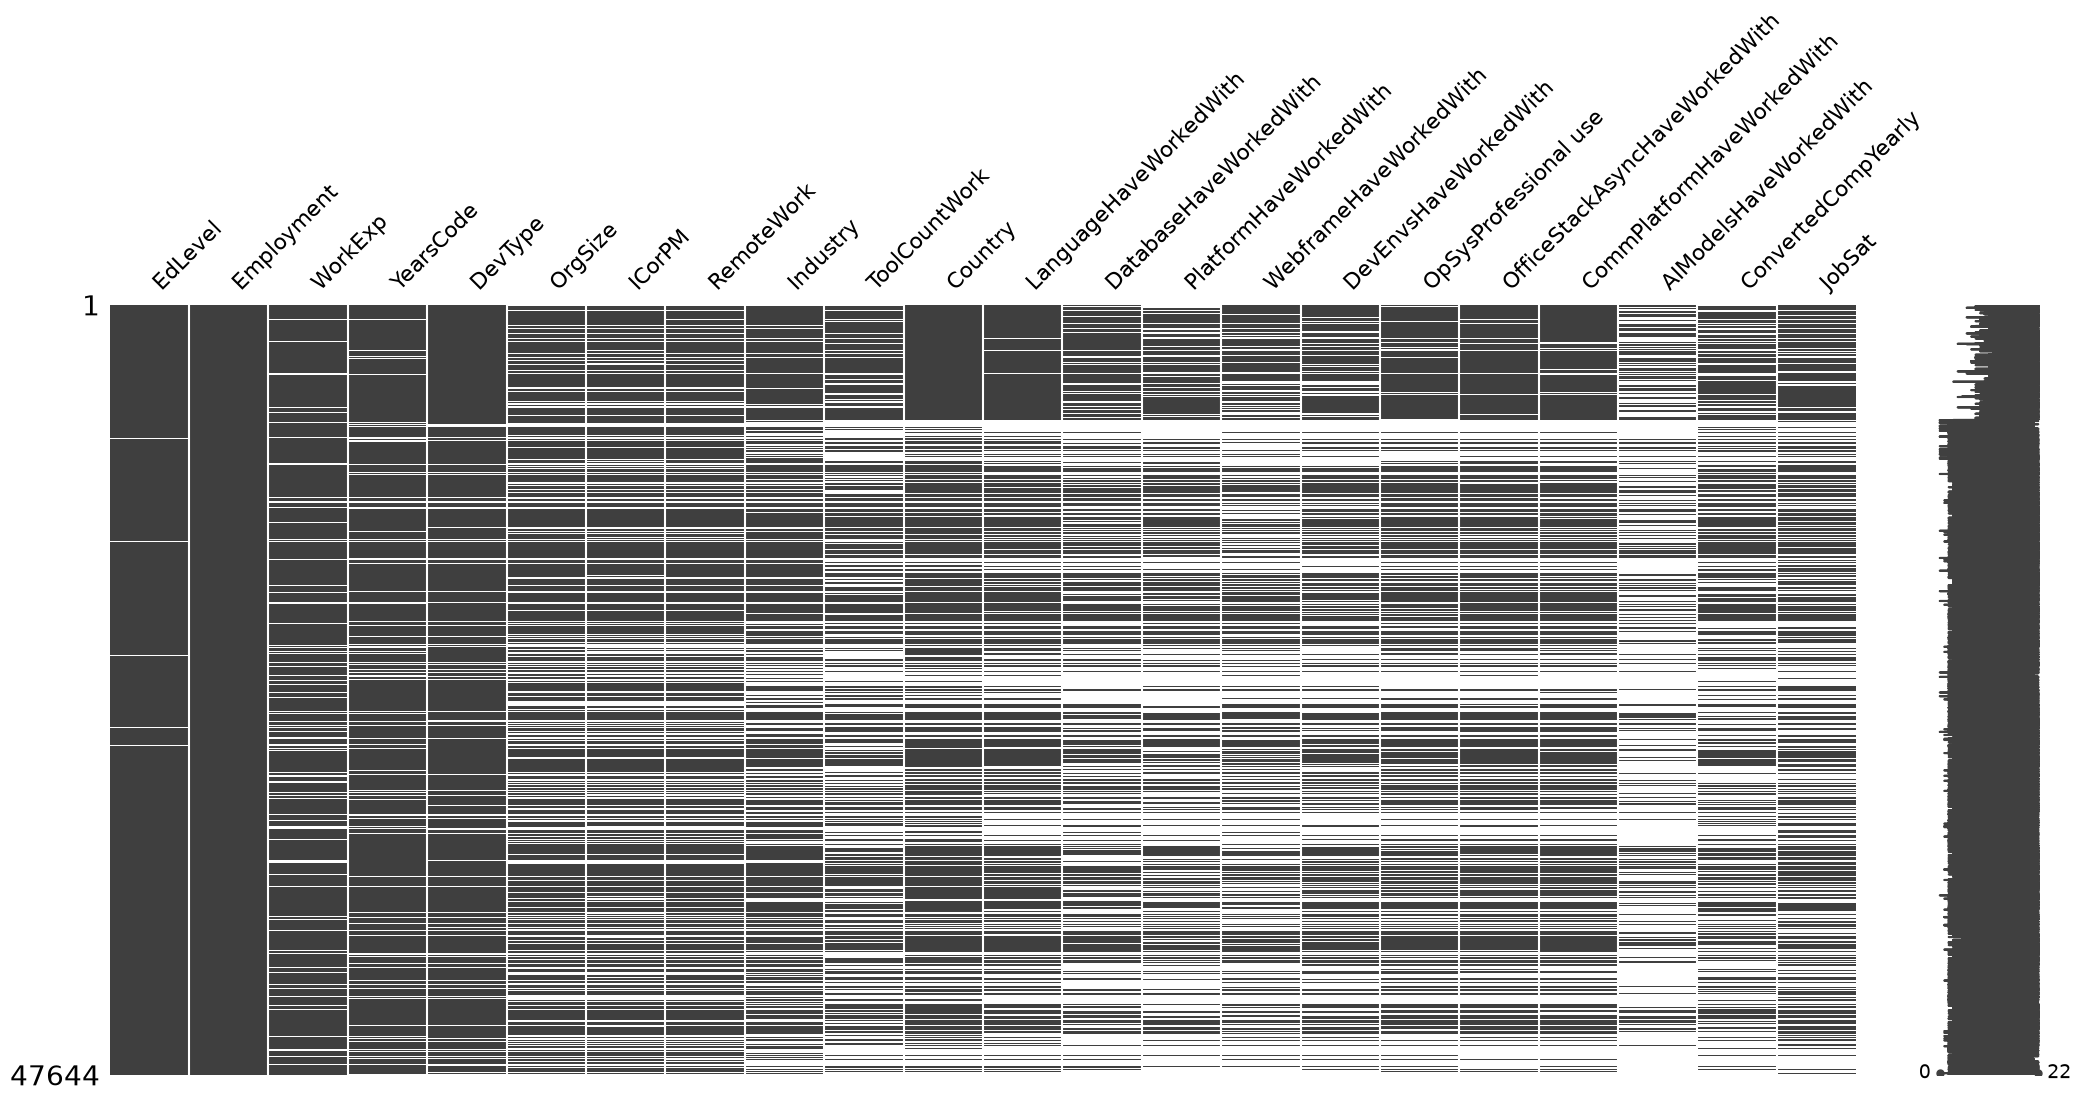

In [3]:
df_hardskills.info()
msno.matrix(df_hardskills)

### 1.4 Revisión de valores nulos

Vemos ahora las columnas que más valores nulos tienen

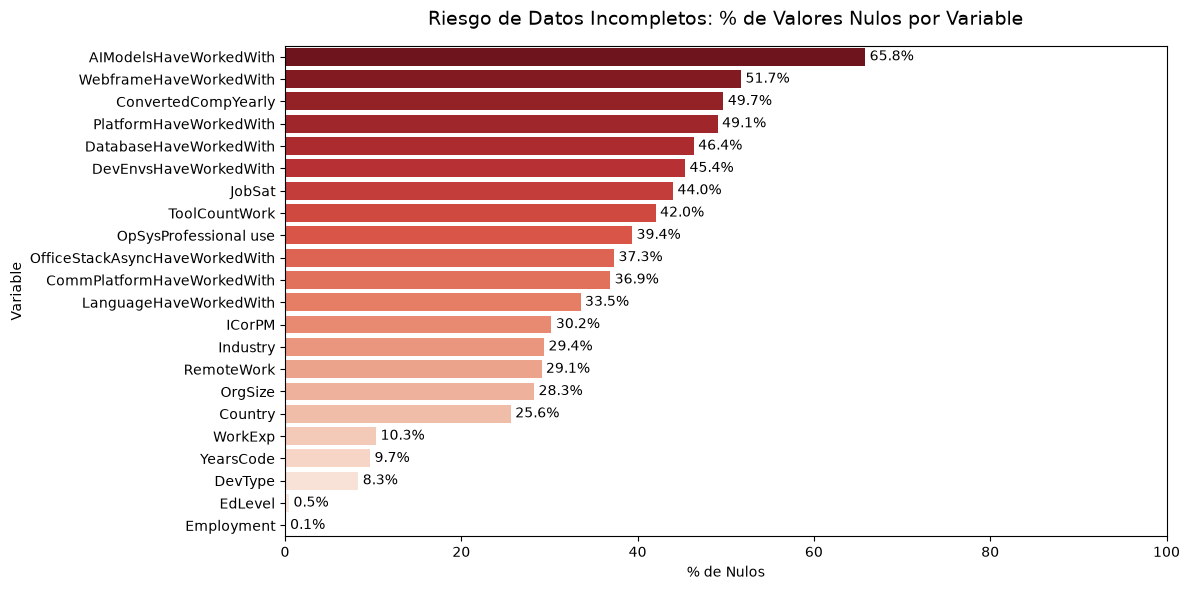

In [4]:
missing_percentage = df_hardskills.isnull().mean() * 100
missing_percentage = missing_percentage[missing_percentage > 0].sort_values(ascending=False)

if not missing_percentage.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=missing_percentage.values, 
        y=missing_percentage.index, 
        palette='Reds_r'
    )
    plt.title('Riesgo de Datos Incompletos: % de Valores Nulos por Variable', fontsize=14, pad=15)
    plt.xlabel('% de Nulos')
    plt.ylabel('Variable')
    for i, valor in enumerate(missing_percentage.values):
        plt.text(valor + 0.5, i, f"{valor:.1f}%", va='center', fontsize=10)
        
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()

### 1.5 Análisis estadístico descriptivo y detección de anomalías

En esta celda calculamos la media, desviación estándar, cuartiles y valores extremos para poder ver cuales son las *Top 5* de categorías más frecuentes para las columnas de texto. 

Este paso es muy importante porque nos cuenta la "historia" de los datos y revela anomalías a simple vista:

1. **El perfil predominante:** Gracias al recuento categórico, vemos que el candidato estándar tiene educación universitaria (*Bachelor's/Master's*), está empleado a tiempo completo, trabaja como *Full-Stack* o *Back-end*, y sus herramientas orbitan alrededor de los ecosistemas de JavaScript/Python y AWS (luego veremos más a detalle)

2. **Detección de Outliers (Valores Atípicos):** Los estadísticos numéricos nos muestran señales de alarma clarísimas. Por ejemplo, en la variable salarial (`ConvertedCompYearly`) vemos un valor máximo de 50 millones de dólares, y un mínimo de 1$. En la cuenta de herramientas (`ToolCountWork`) alguien ha reportado usar 10.000 distintas. 

Estos valores extremos (intencionados o por error de tipeo en la encuesta) destruirían la distribución de pesos y el aprendizaje de la red. Esto justifica matemáticamente y de cara a negocio la necesidad de aplicar filtros restrictivos (*clipping*) en la siguiente fase de limpieza.

In [5]:
print("RESUMEN DE VARIABLES NUMÉRICAS:")
display(df_hardskills.describe().T.round(2))

print("\n\nRESUMEN DE VARIABLES CATEGÓRICAS (Top 5 más frecuentes por columna):")
cat_cols = df_hardskills.select_dtypes(include=['object']).columns

for col in cat_cols:
    print(f"\n--- {col} ---")
    display(df_hardskills[col].value_counts().head(5).to_frame(name='Conteo'))

RESUMEN DE VARIABLES NUMÉRICAS:


,count,mean,std,min,25%,50%,75%,max
WorkExp,42718.0,13.39,10.81,1.0,5.0,10.0,20.0,100.0
YearsCode,43042.0,16.57,11.79,1.0,8.0,14.0,24.0,100.0
ToolCountWork,27611.0,17.73,269.81,0.0,4.0,6.0,10.0,10000.0
ConvertedCompYearly,23947.0,101761.54,461756.90,1.0,38171.0,75320.0,120596.0,50000000.0
JobSat,26670.0,7.20,2.00,0.0,6.0,8.0,8.0,10.0




RESUMEN DE VARIABLES CATEGÓRICAS (Top 5 más frecuentes por columna):

--- EdLevel ---


,Conteo
EdLevel,
"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",19867
"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",12424
Some college/university study without earning a degree,6127
"Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)",3587
"Professional degree (JD, MD, Ph.D, Ed.D, etc.)",2602



--- Employment ---


...

,Conteo
OfficeStackAsyncHaveWorkedWith,
GitHub,2211
GitHub;GitLab,743
Confluence;GitHub;Jira,713
GitHub;Jira,564
GitHub;Markdown File,548



--- CommPlatformHaveWorkedWith ---


,Conteo
CommPlatformHaveWorkedWith,
Stack Overflow,891
Stack Overflow;Stack Exchange,593
"Stack Overflow;Stack Exchange;GitHub (public projects, not private repos)",535
"Stack Overflow;GitHub (public projects, not private repos)",482
"Stack Overflow;Stack Exchange;Reddit;GitHub (public projects, not private repos)",388



--- AIModelsHaveWorkedWith ---


,Conteo
AIModelsHaveWorkedWith,
openAI GPT (chatbot models),2379
Anthropic: Claude Sonnet;openAI GPT (chatbot models),934
openAI GPT (chatbot models);openAI Reasoning models,460
Anthropic: Claude Sonnet,440
openAI GPT (chatbot models);openAI Image generating models;openAI Reasoning models,389


### 1.6 Realizamos limpieza estricta

En esta celda aplicamos nuestra función `limpieza_datos`del módulo `utils`. Esta función realiza las siguientes tareas:

1. **Eliminación de fugas:** Borra los más de 5.000 perfiles duplicados que hemos visto antes.
2. **Filtrado de calidad:** Descarta candidatos "vacíos" que no hayan respondido a las preguntas clave sobre sus herramientas y tecnologías.
3. **Imputación Inteligente (Flags):** En lugar de borrar a los usuarios que no indicaron sus años de experiencia o herramientas, la función rellena los nulos con ceros y crea columnas bandera (ej. `WorkExp_is_missing`, visibles en la tabla resultante). Esto permite a la red neuronal entender que un cero no significa "cero años de experiencia", sino "el usuario no quiso facilitar este dato", capturando así un patrón de comportamiento sin perder al candidato.

*Resultado:* Hemos logrado retener a **44.061 candidatos** limios, formando un bloque sólido sobre el que construir el algoritmo NetSTAFF.

In [6]:
df_clean = utils.limpieza_datos(df_hardskills)
print(f"Transformaciones aplicadas. Candidatos mantenidos: {df_clean.shape[0]}")
display(df_clean.head(3))

Transformaciones aplicadas. Candidatos mantenidos: 39806


,EdLevel,Employment,WorkExp,YearsCode,DevType,OrgSize,ICorPM,RemoteWork,Industry,ToolCountWork,...,JobSat,WorkExp_is_missing,YearsCode_is_missing,ToolCountWork_is_missing,JobSat_is_missing,ConvertedCompYearly_is_missing,EdLevel_is_missing,RemoteWork_is_missing,OrgSize_is_missing,Industry_is_missing
ResponseId,,,,,,,,,,,,,,,,,,,,,
1,6,Employed,8.0,14.0,"Developer, mobile",3,People manager,5,3,7.0,...,10.0,0,0,0,0,0,0,0,0,0
2,4,Employed,2.0,10.0,"Developer, back-end",5,Individual contributor,4,7,6.0,...,9.0,0,0,0,0,0,0,0,0,0
3,5,"Independent contractor, freelancer, or self-em...",10.0,12.0,"Developer, front-end",<NA>,None,<NA>,1,3.0,...,8.0,0,0,0,0,0,0,1,1,0


### 1.7. Tratamiento de salarios (Outliers)

El salario (`ConvertedCompYearly`) sigue mostrando datos poco fiables, por lo que realizamos lo siguiente:

1. **Eliminación de Falsos Positivos:** Reemplazamos los salarios de "0$" (que indican trabajo voluntario, desempleo o errores intencionados) por nulos (`np.nan`).
2. **Imputación por la Mediana:** Rellenamos los vacíos utilizando la **mediana salarial global (~75.320$)**. El motivo por el cual elijo la mediana y no la media es por lo sensible que es a los valores atípicos.
3. **Recorte Estadístico (*Clipping*):** Aplicamos un clipping y así forzamos que ningún salario sea menor de 10.000$ ni mayor de 300.000$. Esto elimina las "colas" extremas de la distribución, evitando que unos pocos valores multimillonarios desvíen los gradientes de nuestra red neuronal durante el entrenamiento.

In [7]:
mediana_salarial = df_clean[df_clean['ConvertedCompYearly'] > 0]['ConvertedCompYearly'].median()
df_clean['ConvertedCompYearly'] = df_clean['ConvertedCompYearly'].replace(0, np.nan)
df_clean['ConvertedCompYearly'] = df_clean['ConvertedCompYearly'].fillna(mediana_salarial)
df_clean['ConvertedCompYearly'] = df_clean['ConvertedCompYearly'].clip(lower=10000, upper=300000)

print(f"Nueva Mediana Salarial: {df_clean['ConvertedCompYearly'].median()}$")

Nueva Mediana Salarial: 75320.0$


### 1.8 Análisis de cardinalidad y combinatoria

Para esta celda realizamos un nuevo conteo de valores únicos por columna. Este paso es básicamente para anticipar la estrategia de codificación (*Feature Engineering*) de la siguiente fase:

1. **Baja Cardinalidad:** Variables categóricas estándar como la educación (`EdLevel`, 8 valores) o el tipo de empleo (`Employment`, 7 valores) son perfectamente manejables y podrán ser transformadas mediante técnicas tradicionales como *One-Hot Encoding*.
2. **Explosión Combinatoria:** Si observamos las variables tecnológicas (ej. `PlatformHaveWorkedWith` con casi 19.000 valores únicos, o `LanguageHaveWorkedWith` con más de 15.000), podemos confirmar que los desarrolladores utilizan combinaciones únicas e infinitas de herramientas. 

Esta altísima cardinalidad justifica que no podemos alimentar a la red neuronal directamente con estas columnas, ya que colapsaría. Esto nos hace cambiar a un algoritmo de extracción multietiqueta (*Multi-label Parsing*) que haremos más adelante.

In [8]:
print(f"{'Columna':<35} | {'Valores Únicos':<15}")
print("-" * 55)

for col in df_clean.columns:
    count = df_clean[col].nunique()
    print(f"{col:<35} | {count:<15}")

Columna                             | Valores Únicos 
-------------------------------------------------------
EdLevel                             | 8              
Employment                          | 6              
WorkExp                             | 63             
YearsCode                           | 65             
DevType                             | 33             
OrgSize                             | 9              
ICorPM                              | 3              
RemoteWork                          | 3              
Industry                            | 12             
ToolCountWork                       | 105            
Country                             | 176            
LanguageHaveWorkedWith              | 14184          
DatabaseHaveWorkedWith              | 6454           
PlatformHaveWorkedWith              | 17812          
WebframeHaveWorkedWith              | 7065           
DevEnvsHaveWorkedWith               | 7324           
OpSysProfessional use     

### 1.9 Validación de coherencia (Experiencia)

En el análisis de encuestas de libre entrada, no basta con buscar nulos o duplicados, tambien debemos auditar la **coherencia lógica** de las respuestas. En esta celda cruzamos dos variables muy relacionadas: los años totales programando (`YearsCode`) frente a los años de experiencia profesional (`WorkExp`).

Para ello, trazamos una "Frontera Lógica" (en la gráfica es la línea roja discontinua). Por lógica, es imposible que un candidato tenga más años de experiencia profesional que años totales codificando. 

Como podemos ver en el gráfico de dispersión, casi un **10% de la muestra (4.389 candidatos)** reporta datos ilógicos, situándose por encima de la frontera. Identificar esta capa de "ruido humano" es vital, ya que nos demuestra que los datos del mundo real son falibles y justifica por qué necesitamos una Red Neuronal Profunda, capaz de ver estas contradicciones e inferir el valor real del candidato a través del resto de sus variables.

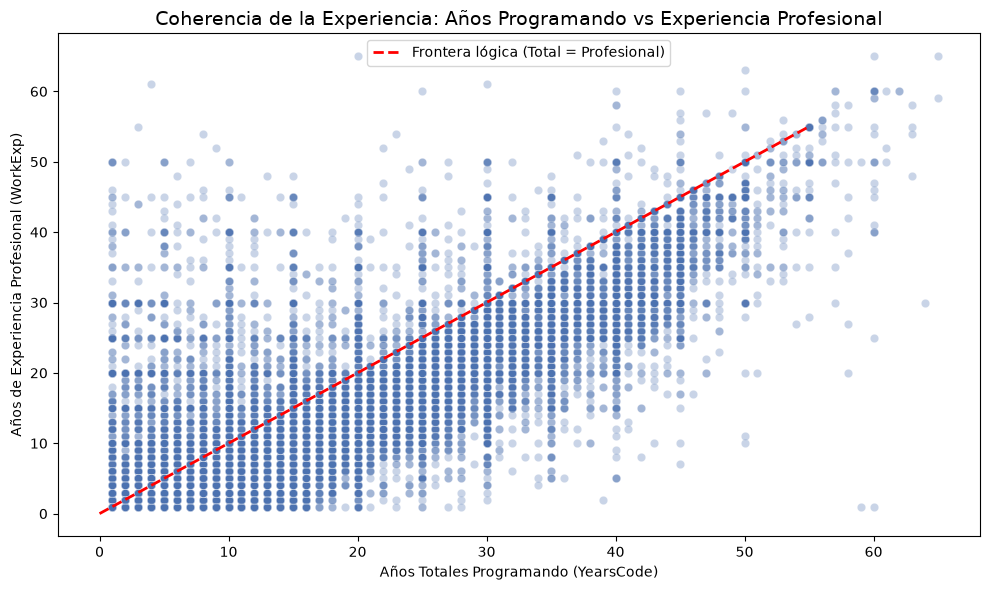

----------------------------------------
Candidatos ilógicos (WorkExp > YearsCode): 3553
Porcentaje de la muestra: 8.93%


In [9]:
df_exp = df_clean.dropna(subset=['YearsCode', 'WorkExp'])

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_exp, x='YearsCode', y='WorkExp', alpha=0.3, color='#4C72B0')
plt.plot([0, 55], [0, 55], color='red', linestyle='--', linewidth=2, label='Frontera lógica (Total = Profesional)')

plt.title('Coherencia de la Experiencia: Años Programando vs Experiencia Profesional', fontsize=14)
plt.xlabel('Años Totales Programando (YearsCode)')
plt.ylabel('Años de Experiencia Profesional (WorkExp)')
plt.legend()
plt.tight_layout()
plt.show()

anomalias = df_exp[df_exp['WorkExp'] > df_exp['YearsCode']]
print("-" * 40)
print(f"Candidatos ilógicos (WorkExp > YearsCode): {len(anomalias)}")
print(f"Porcentaje de la muestra: {(len(anomalias) / len(df_exp)) * 100:.2f}%")

### 1.10 Purga de inconsistencias

Una vez identificado el problema de coherencia temporal en el cruce de variables, procedemos a quitar este ruido. 

Ahora filtramos y conservaremos **exclusivamente** a aquellos candidatos donde sus años totales programando sean mayores o iguales a sus años de experiencia profesional (`YearsCode >= WorkExp`). 

*Resultado:* La purga se completa con éxito, dejándonos **39.672 candidatos**. Estos serán el total de candidatos sobre los que trabajará el modelo.

In [10]:
df_clean = df_clean[df_clean['YearsCode'] >= df_clean['WorkExp']]

print(f"Purga completada.")
print(f"Candidatos restantes: {df_clean.shape[0]}")

Purga completada.
Candidatos restantes: 36253


### 1.11 Taxonomía de Perfiles Tecnológicos (`DevType`)

Tras purgar las inconsistencias, extraemos el catálogo completo de roles profesionales que han sobrevivido en nuestro dataset. Esta variable es, en esencia, la etiqueta principal que define a cada candidato.

Como podemos observar en la salida, el ecosistema se divide en **33 perfiles distintos**. Esta taxonomía abarca todo el espectro de la industria del software: desde los perfiles de desarrollo tradicional (*Full-stack*, *Back-end*, *Mobile*), pasando por la vanguardia de los datos (*AI/ML engineer*, *Data scientist*), hasta llegar a puestos de gestión y liderazgo (*Engineering manager*, *Product manager*). 

Conocer esta nomenclatura nos define el mapa de categorías sobre el cual nuestro futuro motor de recomendación buscará y clasificará a los perfiles más afines a las necesidades del reclutador.

In [11]:
listado_roles = df_clean['DevType'].unique()

print(f"Hay {len(listado_roles)} roles distintos:\n")
for rol in sorted(listado_roles.astype(str)):
    print(f"- {rol}")

Hay 33 roles distintos:

- AI/ML engineer
- Academic researcher
- Applied scientist
- Architect, software or solutions
- Cloud infrastructure engineer
- Cybersecurity or InfoSec professional
- Data engineer
- Data or business analyst
- Data scientist
- Database administrator or engineer
- DevOps engineer or professional
- Developer, AI apps or physical AI
- Developer, QA or test
- Developer, back-end
- Developer, desktop or enterprise applications
- Developer, embedded applications or devices
- Developer, front-end
- Developer, full-stack
- Developer, game or graphics
- Developer, mobile
- Engineering manager
- Financial analyst or engineer
- Founder, technology or otherwise
- None
- Other (please specify):
- Product manager
- Project manager
- Retired
- Senior executive (C-suite, VP, etc.)
- Student
- Support engineer or analyst
- System administrator
- UX, Research Ops or UI design professional


### 1.12 Selección de perfiles contratables

Nuestro algoritmo de recomendación debe ofrecer exclusivamente perfiles que sean viables y útiles en el mercado laboral real.

En esta celda aplicamos nuestra última regla de negocio: eliminamos explícitamente aquellos roles que, por su naturaleza, no son el objetivo de una búsqueda activa de talento profesional. Esto incluye a estudiantes (`Student`), profesionales jubilados (`Retired`) y perfiles genéricos sin clasificar (`Other`). 

*Resultado Final:* Tras esta última purga de negocio, nuestro *dataset* se queda con **35.288 candidatos**. Esta es nuestra "bolsa de talento" definitiva: un conjunto de datos maduro, lógicamente coherente y 100% contratable.

In [12]:
roles_a_eliminar = [
    'Retired', 
    'Student', 
    'Other (please specify):'
]

df_clean = df_clean.dropna(subset=['DevType'])
df_clean = df_clean[~df_clean['DevType'].isin(roles_a_eliminar)]

print(f"Candidatos finales realmente contratables: {df_clean.shape[0]}")

Candidatos finales realmente contratables: 33880


### 1.13 Distribución del Mercado

Con nuestro *dataset* final consolidado y purgado, visualizamos la distribución real de los distintos perfiles tecnológicos. Con este gráfico de barras podemos ver qué perfiles son los más abundantes y cuáles son menos comunes en el sector.

También verificamos lo siguiente:
1. **Integridad Total:** Tenemos **0 nulos** en (`DevType`). Todos los candidatos que entran a la fase de modelado están perfectamente etiquetados.
2. **El Dominio Full-Stack:** El rol de *Developer, full-stack* es el rey indiscutible del mercado, acaparando el **33.0%** de toda nuestra base de talentos, seguido de cerca por los desarrolladores *Back-end*. 

Desde una perspectiva de *Recruiting* e Inteligencia Artificial, esto significa que nuestra red neuronal tendrá muchísimos ejemplos para aprender el "ADN" de un desarrollador web tradicional. Sin embargo, tendrá que afinar para lograr recomendar con éxito perfiles altamente especializados y minoritarios (como ingenieros de *Machine Learning* o arquitectos *Cloud*).

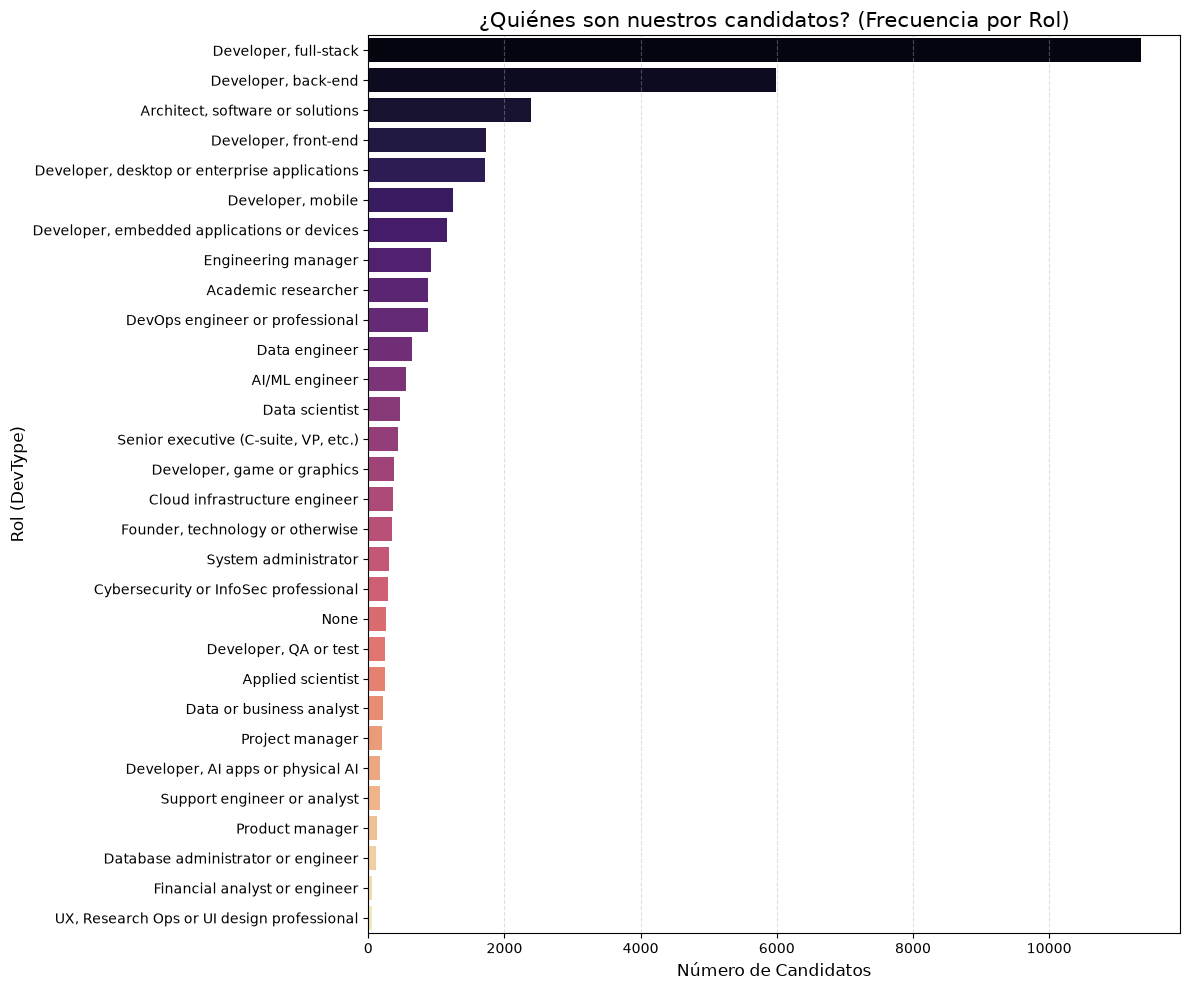

Atención: Hay 0 candidatos sin rol definido (nan).
El rol dominante es 'Developer, full-stack' representando el 33.5% del talento disponible.


In [13]:
role_counts = df_clean['DevType'].value_counts(dropna=False)
plt.figure(figsize=(12, 10))
sns.barplot(x=role_counts.values, y=role_counts.index, palette='magma')
plt.title('¿Quiénes son nuestros candidatos? (Frecuencia por Rol)', fontsize=15)
plt.xlabel('Número de Candidatos', fontsize=12)
plt.ylabel('Rol (DevType)', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()
nulos_dev = df_clean['DevType'].isna().sum()
print(f"Atención: Hay {nulos_dev} candidatos sin rol definido (nan).")

total_contratables = len(df_clean)
top_rol = role_counts.index[0]
porcentaje_top = (role_counts.values[0] / total_contratables) * 100

print(f"El rol dominante es '{top_rol}' representando el {porcentaje_top:.1f}% del talento disponible.")

### 1.14 Madurez Tecnológica y seniors por rol

Para profundizar un poco más, generamos un diagrama de cajas (*boxplot*) cruzando los 10 roles más predominantes con sus años totales de experiencia programando (`YearsCode`). Para maximizar que se vea más claro ordenamos las categorías dinámicamente en función de su mediana.

*¿Qué nos dice este gráfico a nivel de negocio?* Confirma de forma visual y empírica la progresión natural de la carrera en el sector IT:

1. **Punto de entrada:** Roles de inicio o enfocados en la capa visual (como *Student* o *Developer, front-end*) presentan las medianas de experiencia más bajas (en torno a 5-8 años).
2. **Madurez y Liderazgo:** Por el contrario, roles con alta carga arquitectónica, de sistemas heredados o de gestión de equipos (*Desktop/enterprise applications* o *Engineering manager*) exigen una madurez tecnológica muchísimo mayor, situando su mediana cómodamente por encima de los 15 años de código.

Esta validación cruzada nos asegura que los datos reflejan fielmente la realidad del mercado laboral. Nuestra futura red neuronal aprenderá estas asociaciones de forma implícita, entendiendo que no debe recomendar a un candidato con 3 años de experiencia para un puesto de *Engineering Manager*.

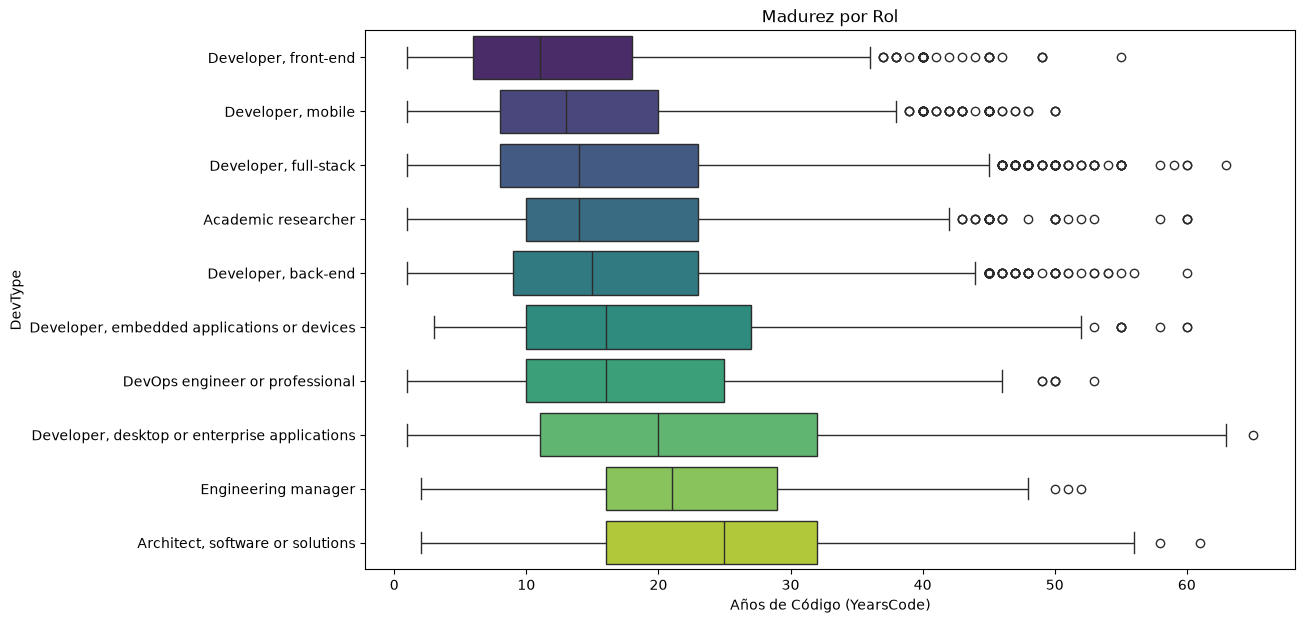

In [14]:
df_clean = df_clean.dropna(subset=['DevType'])
top_roles = df_clean['DevType'].value_counts().head(10).index
df_plot = df_clean[df_clean['DevType'].isin(top_roles)]
plt.figure(figsize=(12, 7))
order = df_plot.groupby('DevType')['YearsCode'].median().sort_values().index

sns.boxplot(data=df_plot, x='YearsCode', y='DevType', order=order, palette='viridis')
plt.title('Madurez por Rol')
plt.xlabel('Años de Código (YearsCode)')
plt.show()

### 1.15 Análisis de Varianza: ¿Basta la experiencia para predecir el rol?

En este diagrama de cajas planteamos una pregunta : *"Si sabemos cuántos años lleva programando un candidato, ¿podemos deducir su puesto?"*

Al ver la dispersión completa de roles sin filtrar, nos dice que **los rangos intercuartílicos (las cajas) se solapan masivamente**. Salvo ligeras excepciones en la base (estudiantes) o en la cima (directivos), un profesional con 10 años de experiencia (`YearsCode = 10`) podría encajar matemáticamente en más de 25 roles distintos. 

**Conclusión técnica:** Este solapamiento demuestra que crear un sistema de recomendación basado en reglas simples ("*Si tiene X años, recomiéndalo para Y puesto*") es un enfoque inútil y destinado al fracaso. La experiencia por sí sola no define a un desarrollador. Nos reafirma la necesidad de utilizar el modelo de **Deep Learning** para desentrañar a qué rol pertenece realmente el candidato.

Text(0.5, 1.0, '¿La experiencia ayuda a distinguir el puesto?')

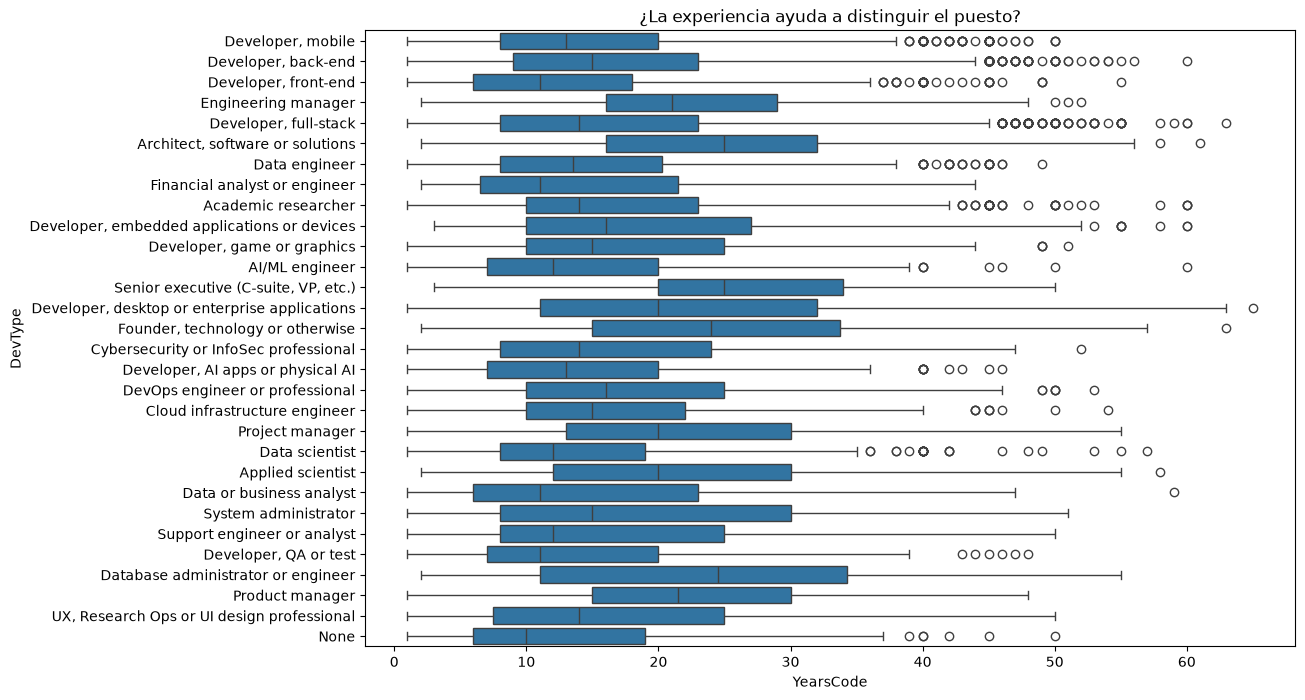

In [15]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=df_clean, x='YearsCode', y='DevType')
plt.title('¿La experiencia ayuda a distinguir el puesto?')

### 1.16 Lenguajes más dominantes en la industria

En esta celda tratamos de ver que lenguajes son los más comunes entre los distintos candidatos del dataset. Los resultados nos muestran lo siguiente:

1. **La Hegemonía Web y de datos:** JavaScript (con casi 20.000 usuarios), HTML/CSS, Python y SQL lideran la tabla de forma aplastante. Nuestro sistema deberá ser muy fino al evaluar estos lenguajes, ya que estarán presentes en la inmensa mayoría de los currículums y por sí solos no servirán para diferenciar a un candidato "bueno" de uno "excelente".

2. **Justificación de dimensionalidad:** Observamos que la adopción cae drásticamente a medida que descendemos en el ranking (el lenguaje en la posición 30 tiene 10 veces menos presencia que el líder). Esta caída en picado justifica la decisión técnica que aplicaremos en la **Libreta 2**: limitar la extracción de variables a las herramientas principales (`top_n=20`) para evitar que lenguajes residuales y de nicho saturen la red neuronal con dimensiones casi vacías.

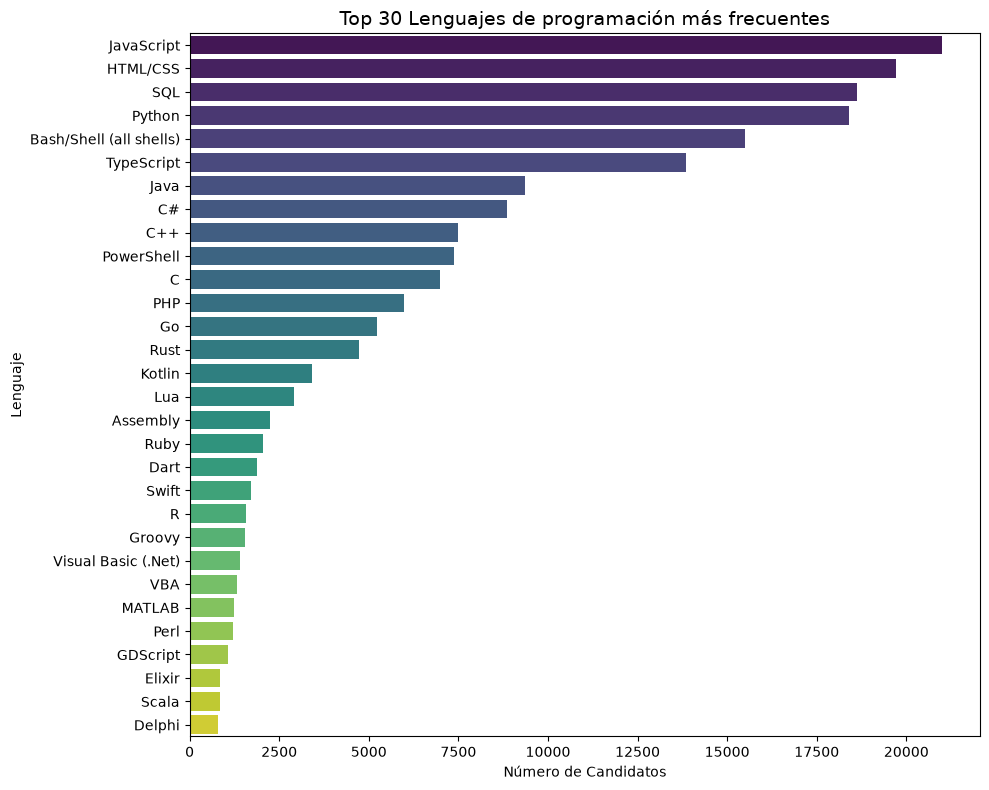

El lenguaje más común es JavaScript con 21005 usuarios.
El lenguaje número 30 es Delphi con 796 usuarios.


In [16]:
top_languages = df_hardskills['LanguageHaveWorkedWith'].str.get_dummies(sep=';').sum().sort_values(ascending=False)
plt.figure(figsize=(10, 8))
sns.barplot(x=top_languages.head(30).values, y=top_languages.head(30).index, palette='viridis')

plt.title('Top 30 Lenguajes de programación más frecuentes', fontsize=14)
plt.xlabel('Número de Candidatos')
plt.ylabel('Lenguaje')
plt.tight_layout()
plt.show()
print(f"El lenguaje más común es {top_languages.index[0]} con {top_languages.iloc[0]} usuarios.")
print(f"El lenguaje número 30 es {top_languages.index[29]} con {top_languages.iloc[29]} usuarios.")

### 1.17 Nivel educativo de los candidatos

Con la siguiente gráfica podemos ver lo siguiente:

1. **La norma es universitaria:** Aproximadamente el **70%** del mercado posee un título universitario superior (*Bachelor's degree* con un ~43% y *Master's degree* con un ~26%). Esto establece que nuestra bolsa de candidatos tiene una base académica altísima.
2. **El valor de las rutas alternativas:** Sin embargo, un porcentaje bajo (más del 12%) corresponde a profesionales con estudios universitarios incompletos o formación no tradicional. Esto refleja que el no tener un título univesitario no es un bloqueo absoluto si se demuestran habilidades técnicas excepcionales.

Para nuestra futura Red Neuronal, la variable `EdLevel` será un factor importante, pero este gráfico demuestra que el modelo no podrá basarse únicamente en el título; deberá aprender a balancear la falta de un diploma oficial ponderando positivamente una mayor experiencia (`YearsCode`) o un ecosistema tecnológico avanzado.

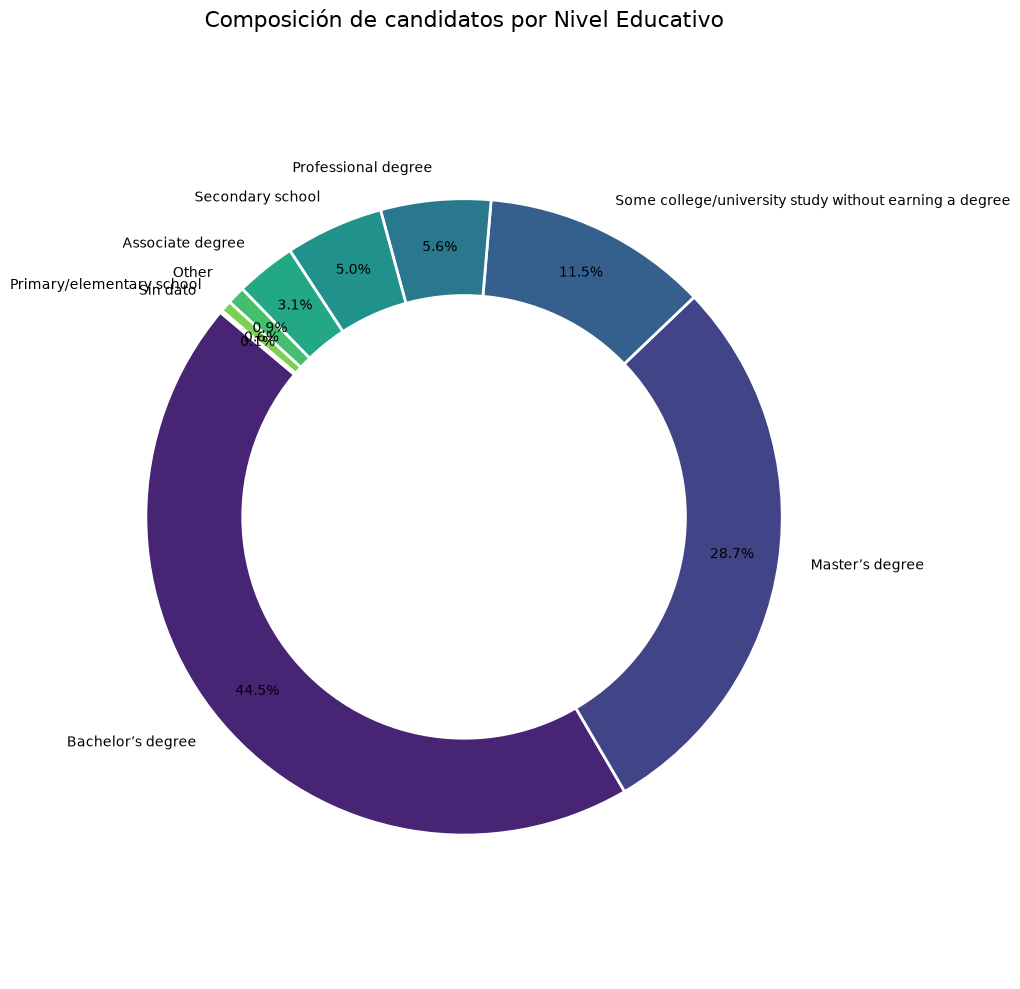

In [17]:
inv_ed_map = {v: k.split(' (')[0] for k, v in config.ED_LEVEL_MAPPING.items()}

df_plot_ed = df_clean.copy()
df_plot_ed['EdLevel_Label'] = df_plot_ed['EdLevel'].map(inv_ed_map).fillna('Sin dato')
ed_counts = df_plot_ed['EdLevel_Label'].value_counts()

plt.figure(figsize=(10, 10))
colores = sns.color_palette('viridis', len(ed_counts))

plt.pie(
    ed_counts, 
    labels=ed_counts.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    pctdistance=0.85, 
    colors=colores,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Composición de candidatos por Nivel Educativo', fontsize=16, pad=20)
plt.axis('equal') 
plt.tight_layout()
plt.show()

### 1.18. El Paradigma Actual

Ahora analizamos la modalidad de trabajo (`RemoteWork`). En esta ocasión, optamos por un **gráfico tipo Waffle**, que permite visualizar las proporciones de una manera mucho más intuitiva.

Los datos revelan el paradigma laboral post-pandemia en el sector IT:

1. **La Hegemonía del Remoto:** Con un **44.0%**, el trabajo 100% remoto es la modalidad predominante. El talento tecnológico actual asume la deslocalización como un estándar de la industria.
2. **El Empate Técnico:** Las modalidades presenciales (*In-person*, 28.4%) e híbridas (*Hybrid*, 27.6%) se reparten el resto del pastel casi a partes iguales.

**Implicación para NetSTAFF:** Esta variable es un "filtro duro" (*deal-breaker*) en el mundo del reclutamiento. Si nuestro motor de recomendación encuentra a un candidato técnicamente perfecto, pero que exige trabajo remoto 100% para una oferta estrictamente presencial, el emparejamiento fracasará en el mundo real. La red neuronal deberá aprender a alinear esta expectativa de vida con los requerimientos del proyecto.

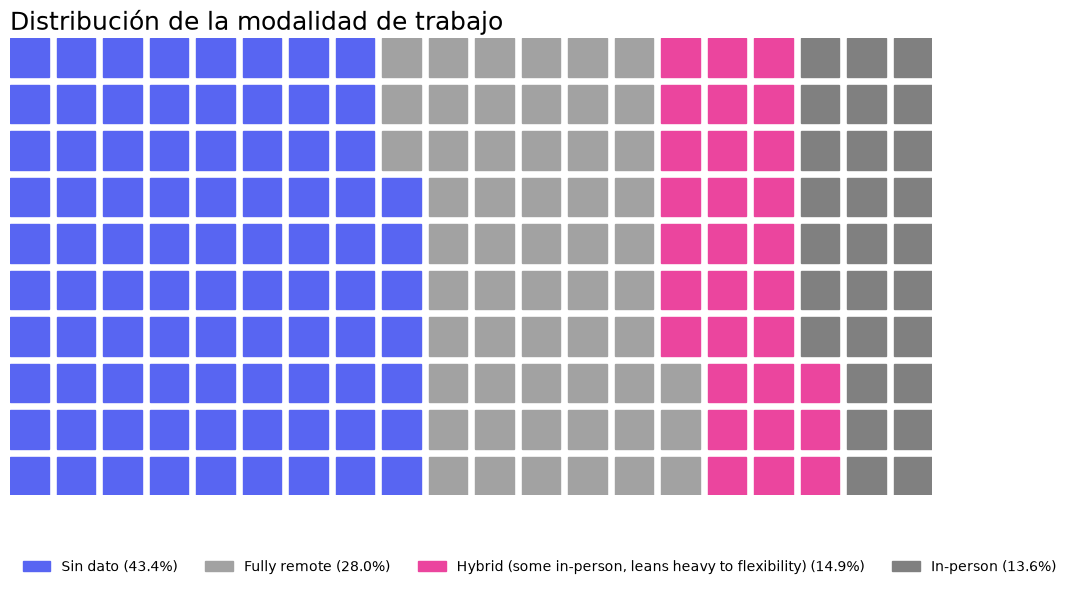

In [18]:
inv_remote_map = {v: k for k, v in config.MAPEO_MODALIDADES.items()}
df_plot_remote = df_clean.copy()
df_plot_remote['Remote_Label'] = df_plot_remote['RemoteWork'].map(inv_remote_map).fillna('Sin dato')
data_counts = df_plot_remote['Remote_Label'].value_counts()
proporciones = (data_counts / len(df_plot_remote) * 100).to_dict()

colores_base = ["#5865F2", "#A2A2A2", "#EB459E"]
colores_finales = colores_base[:len(proporciones)] if len(proporciones) <= len(colores_base) else colores_base + sns.color_palette("gray", len(proporciones) - len(colores_base)).as_hex()

fig = plt.figure(
    FigureClass=Waffle,
    rows=10, 
    columns=20,
    values=proporciones,
    colors=colores_finales,
    title={'label': 'Distribución de la modalidad de trabajo', 'loc': 'left', 'fontdict': {'fontsize': 18}},
    labels=[f"{k} ({v:.1f}%)" for k, v in proporciones.items()],
    legend={'loc': 'lower left', 'bbox_to_anchor': (0, -0.2), 'ncol': len(data_counts), 'frameon': False},
    figsize=(12, 6)
)

plt.show()

### 1.19 Tamaño de la Organización

Para entender el contexto corporativo del que provienen nuestros candidatos, miramos la variable `OrgSize` y extraemos su catálogo completo. 

Si observamos podemos ver que nuestra bolsa de talento abarca **9 ecosistemas empresariales distintos**, cubriendo absolutamente todo el espectro del mercado: desde perfiles *Freelance* (Cod 1) y talento de pequeñas Startups (Cod 2, menos de 20 empleados), hasta perfiles

**Implicación para el modelo:** El tamaño de la empresa es un indicador vital del "tipo" de experiencia del candidato. La futura Red Neuronal utilizará esta variable para entender la adaptabilidad del desarrollador, asumiendo que el flujo de trabajo, la agilidad y las metodologías varían drásticamente dependiendo de la magnitud de la organización.

In [19]:
inv_org_map = {int(v): k for k, v in config.ORG_SIZE_MAPPING.items() if v != 0}
inv_org_map[0] = "Unknown/Other"

serie_valores = df_clean['OrgSize']
valores_no_nulos = sorted(serie_valores.dropna().unique())
n_nulos = serie_valores.isna().sum()

print(f"Hay {len(valores_no_nulos)} tamaños de organización distintos (sin contar 'sin dato'), y {n_nulos} candidatos sin dato registrado:\n")

for tamano_num in valores_no_nulos:
    nombre_texto = inv_org_map.get(int(tamano_num), "Desconocido")
    print(f"- [Cod {int(tamano_num)}] : {nombre_texto}")

if n_nulos > 0:
    print(f"- [Sin dato] : {n_nulos} candidatos ({n_nulos/len(df_clean)*100:.1f}%) no proporcionaron esta información")

Hay 9 tamaños de organización distintos (sin contar 'sin dato'), y 5100 candidatos sin dato registrado:

- [Cod 0] : Unknown/Other
- [Cod 1] : Just me - I am a freelancer, sole proprietor, etc.
- [Cod 2] : Less than 20 employees
- [Cod 3] : 20 to 99 employees
- [Cod 4] : 100 to 499 employees
- [Cod 5] : 500 to 999 employees
- [Cod 6] : 1,000 to 4,999 employees
- [Cod 7] : 5,000 to 9,999 employees
- [Cod 8] : 10,000 or more employees
- [Sin dato] : 5100 candidatos (15.1%) no proporcionaron esta información


### 1.20 Distribución del ecosistema empresarial

Para esta diapositiva generamos un **gráfico de mapa de árbol (*Treemap*)** utilizando la librería `squarify`.

El gráfico resultante es una excelente noticia para nuestro recomendador, ya que nos muestra una distribución extraordinariamente equilibrada del talento:
1. **El motor de las PYMES:** Las empresas de tamaño pequeño y mediano (los bloques de 20 a 499 empleados) agrupan a casi el 40% de los candidatos.
2. **Representación en los extremos:** Tenemos una presencia muy sólida tanto de entornos ágiles tipo *Startup* (menos de 20 empleados, 16.2%), como de gigantes corporativos y multinacionales (más de 10.000 empleados, 14.6%).

**Conclusión de negocio:** Nuestro *dataset* es rico, diverso y carece de sesgo corporativo. Esto garantiza que la Inteligencia Artificial tendrá ejemplos suficientes para aprender a diferenciar el "ADN" de un programador acostumbrado al ritmo frenético de una *startup* frente al de un ingeniero habituado a la escala y burocracia de una gran corporación.

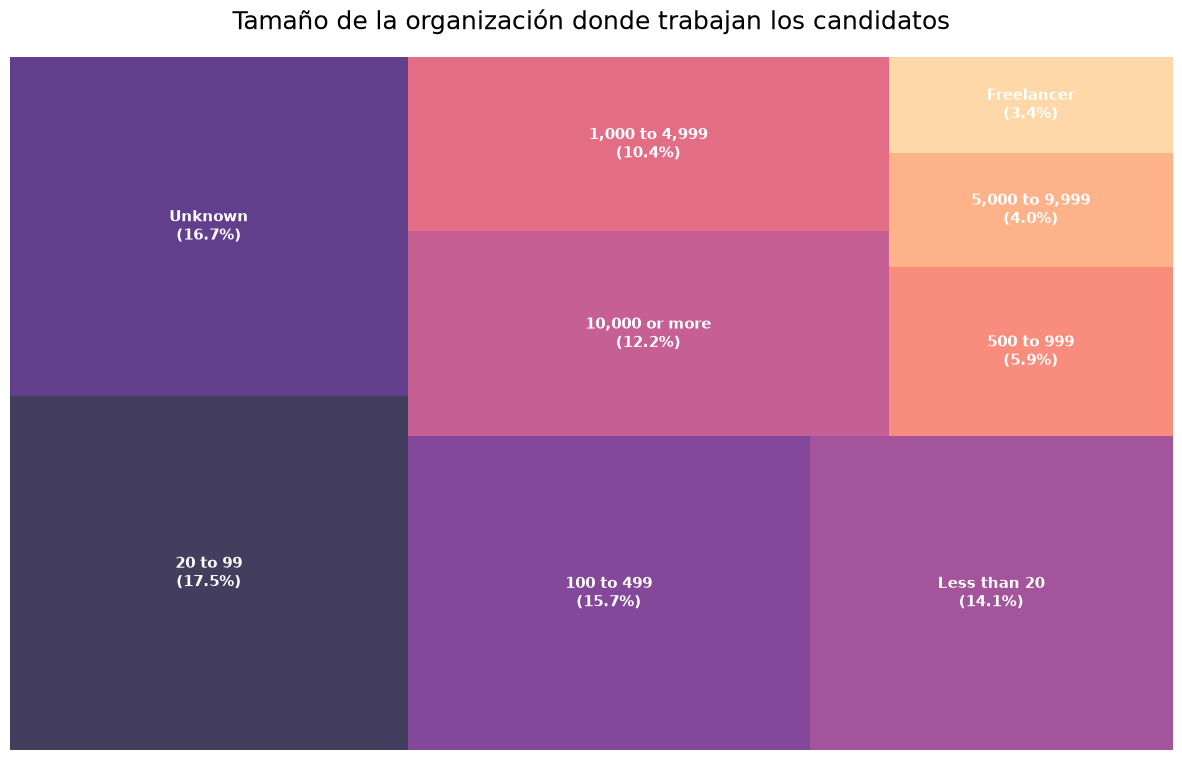

In [20]:
df_plot_org = df_clean.copy()
if df_plot_org['OrgSize'].dtype == object:
    df_plot_org['OrgSize'] = df_plot_org['OrgSize'].map(config.ORG_SIZE_MAPPING).fillna(0)

df_plot_org['OrgSize_Int'] = df_plot_org['OrgSize'].fillna(0).astype(int)
inv_org_map = {
    int(v): k.replace(' employees', '').replace('Just me - I am a freelancer, sole proprietor, etc.', 'Freelancer') 
    for k, v in config.ORG_SIZE_MAPPING.items() if v != 0
}
inv_org_map[0] = "Unknown"
df_plot_org['Org_Label'] = df_plot_org['OrgSize_Int'].map(inv_org_map)
counts = df_plot_org['Org_Label'].value_counts()
labels = [f"{n}\n({(c/len(df_plot_org)*100):.1f}%)" for n, c in zip(counts.index, counts.values)]

plt.figure(figsize=(15, 9))
squarify.plot(
    sizes=counts.values, 
    label=labels, 
    alpha=0.8, 
    color=sns.color_palette("magma", len(counts)),
    text_kwargs={'fontsize': 11, 'weight': 'bold', 'color': 'white'}
)

plt.title('Tamaño de la organización donde trabajan los candidatos', fontsize=18, pad=20)
plt.axis('off')
plt.show()

### 1.21 Distribución por sectores

Ahora, analizamos el sector económico en el que nuestros candidatos desarrollan su actividad.

El resultado nos despliega un abanico de **12 sectores** bien definidos. Aunque el desarrollo de software puro (`Software Development`) y las telecomunicaciones (`Internet/Telecomm`) son la fuerza mayoritaria, contamos con talento en sectores altamente regulados y específicos como la Banca (`Banking/Financial Services`), la Salud (`Healthcare`) o el sector Gubernamental (`Government`).

**El valor para NetSTAFF:** Esta variable aporta lo que en Recursos Humanos se conoce como *Domain Expertise* (experiencia en el dominio). Nuestra red neuronal utilizará este dato para entender que un perfil tecnológico no solo se define por sus lenguajes de programación, sino por su conocimiento del negocio. Si un reclutador busca un perfil para un proyecto *Fintech*, el modelo aprenderá a priorizar sutilmente a aquellos candidatos que ya entienden la idiosincrasia y los estándares de seguridad del sector financiero.

In [21]:
inv_industry_map = {}
for k, v in config.INDUSTRY_MAPPING.items():
    if v not in inv_industry_map and v != 0:
        inv_industry_map[v] = k
inv_industry_map[0] = "Unknown/Other"

serie_valores = df_clean['Industry']
valores_no_nulos = sorted(serie_valores.dropna().unique())
n_nulos = serie_valores.isna().sum()

print(f"Hay {len(valores_no_nulos)} sectores distintos\n")

for ind_num in valores_no_nulos:
    nombre_texto = inv_industry_map.get(int(ind_num), "Desconocido")
    print(f"- [Cod {int(ind_num)}] : {nombre_texto}")

if n_nulos > 0:
    print(f"- [Sin dato] : {n_nulos} candidatos ({n_nulos/len(df_clean)*100:.1f}%) no proporcionaron esta información")

Hay 12 sectores distintos

- [Cod 0] : Unknown/Other
- [Cod 1] : Software Development
- [Cod 2] : Internet, Telecomm or Information Services
- [Cod 3] : Banking/Financial Services
- [Cod 4] : Healthcare
- [Cod 5] : Manufacturing
- [Cod 6] : Government
- [Cod 7] : Retail and Consumer Services
- [Cod 8] : Higher Education
- [Cod 9] : Energy
- [Cod 10] : Transportation, or Supply Chain
- [Cod 11] : Media & Advertising Services
- [Sin dato] : 5410 candidatos (16.0%) no proporcionaron esta información


### 1.22 Visualización del mapa de especialización sectorial

De la gráfica y el recuento de consola extraemos dos aprendizajes fundamentales para el modelado:

1. **El núcleo duro frente al nicho:** Como era esperable, la industria pura del software (*Software Development* e *Internet/Telecomm*) domina el mercado. Sin embargo, la presencia escalonada en sectores regulados como *Banking/Financial Services* o *Healthcare* nos asegura que el modelo tendrá ejemplos suficientes para aprender a hacer recomendaciones en nichos de alta especialización.

2. **Retención Estratégica de Datos:** El código nos señala de que unos 8.500 candidatos cayeron en la categoría *Unknown/Other* (no especificaron su sector). En lugar de eliminarlos y perder su información (lenguajes, años de experiencia, salario), los hemos agrupado en una categoría neutra. De este modo, la red neuronal sabrá que estos perfiles son "agnósticos" al sector y basará su recomendación puramente en su excelencia técnica.

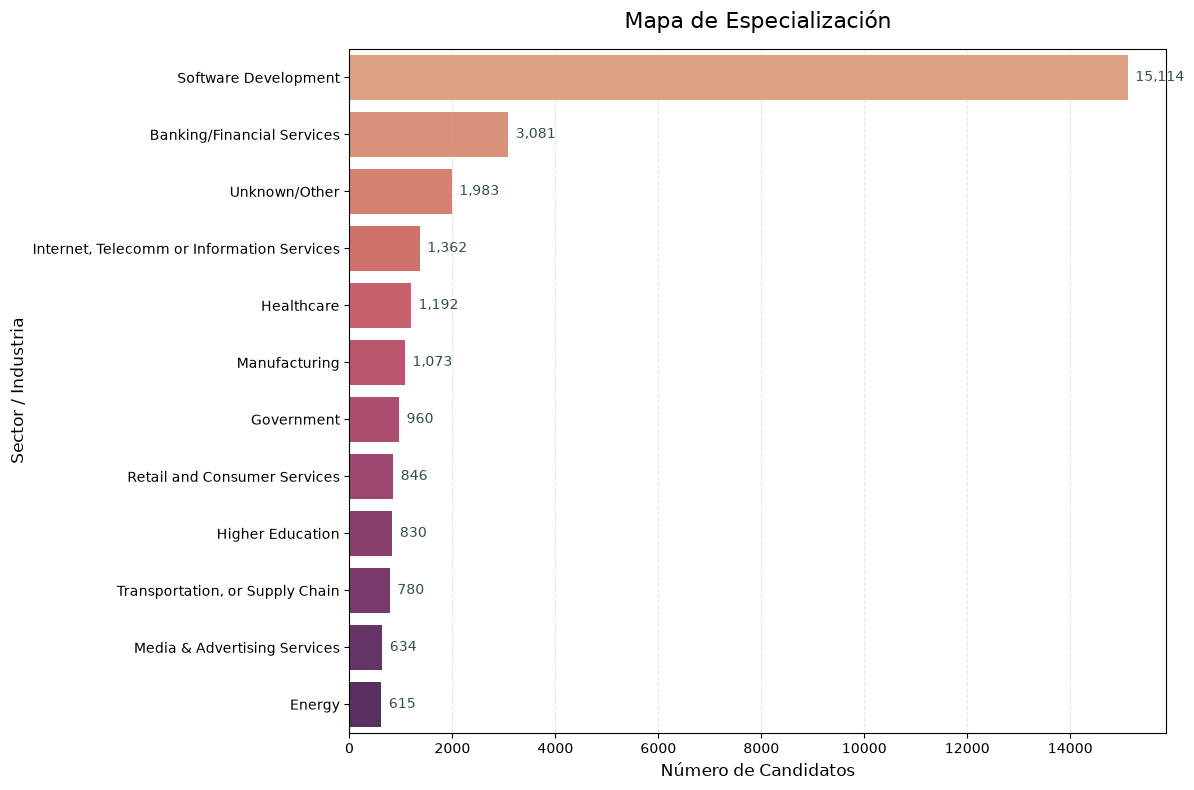

Nota: Hay 1,983 candidatos clasificados como 'Unknown/Other' (incluye aquellos que no especificaron).


In [22]:
inv_industry_map = {}
for k, v in config.INDUSTRY_MAPPING.items():
    if v not in inv_industry_map and v != 0:
        inv_industry_map[v] = k
inv_industry_map[0] = "Unknown/Other"

df_plot_ind = df_clean.copy()
df_plot_ind['Industry_Label'] = df_plot_ind['Industry'].map(inv_industry_map)
ind_counts = df_plot_ind['Industry_Label'].value_counts()
plt.figure(figsize=(12, 8))
sns.barplot(
    x=ind_counts.values, 
    y=ind_counts.index, 
    palette='flare'
)

plt.title('Mapa de Especialización', fontsize=16, pad=15)
plt.xlabel('Número de Candidatos', fontsize=12)
plt.ylabel('Sector / Industria', fontsize=12)

for i, valor in enumerate(ind_counts.values):
    plt.text(valor + 150, i, f"{valor:,}", va='center', fontsize=10, color='darkslategrey')

plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

nulos_ind = (df_clean['Industry'] == 0).sum()
print(f"Nota: Hay {nulos_ind:,} candidatos clasificados como 'Unknown/Other' (incluye aquellos que no especificaron).")

### 1.23 Enriquecimiento de datos y distribución geográfica

En esta celda damos un paso más allá del *dataset* original realizando una operación clave: **Enriquecimiento de Datos** (*Data Enrichment*). Importamos un diccionario geográfico auxiliar (`PAISES_MAPA_PATH`) y lo fusionamos (*merge*) con nuestra base de talento. Esto nos permite mapear cada país individual con su continente y huso horario correspondiente.

Al proyectar esta nueva variable geográfica en un gráfico de anillo, extraemos un contexto importantísimo para la estrategia de contratación:

1. **Concentración Occidental:** Europa (44.5%) y Norteamérica (27.5%) aglutinan más del 70% de nuestra bolsa de talento. Asia se posiciona como el tercer gran núcleo con un 16.5%.

2. **El Valor de la Zona Horaria:** Al inyectar el continente y el huso horario, dotamos a **NetSTAFF** de información logística vital. En la era del trabajo remoto (que vimos que dominaba en gráficas anteriores), el algoritmo no solo podrá buscar al perfil técnicamente más apto, sino que permitirá a Recursos Humanos filtrar candidatos que operen en una ventana horaria compatible con el resto del equipo de desarrollo.

In [23]:
if not os.path.exists(config.PAISES_MAPA_PATH):
    print("Generando CSV maestro de países para el mapa")
    utils.datos_geografia(df_clean['Country'])
else:
    print(f"Maestro de países ya existe en {config.PAISES_MAPA_PATH}, se reutiliza sin llamar a la API.")

Generando CSV maestro de países para el mapa
CSV de países guardado en: /run/media/miguel-angel/Datos compartidos/TFM/data/processed/maestro_paises_mapa.csv


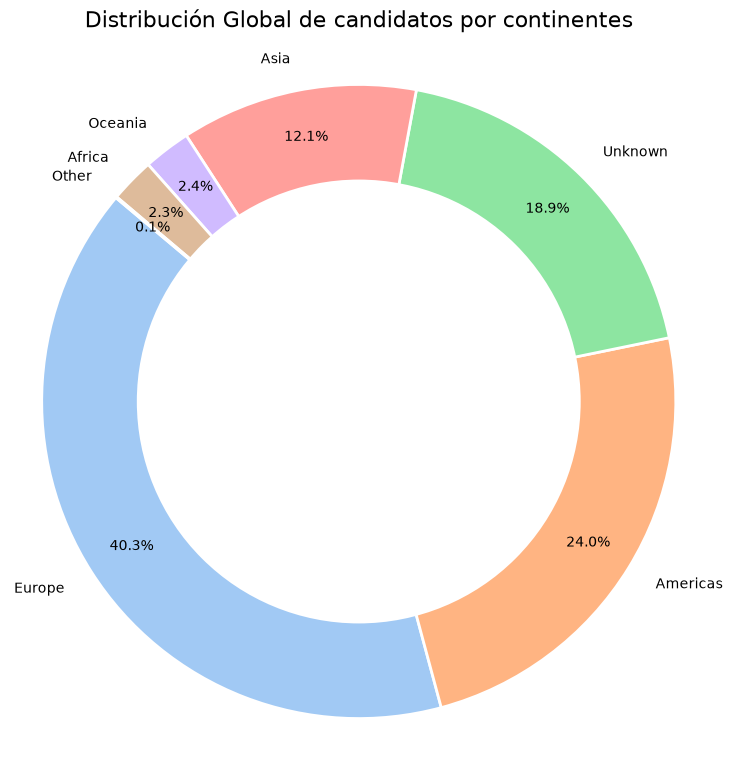

In [24]:
df_paises = pd.read_csv(config.PAISES_MAPA_PATH, sep=';')

cols_a_borrar = ['Continente', 'Zonas_Horarias', 'Pais_Original']
for col in cols_a_borrar:
    if col in df_clean.columns:
        df_clean = df_clean.drop(columns=[col])

df_clean = df_clean.merge(
    df_paises[['Pais_Original', 'Continente', 'Zonas_Horarias']], 
    left_on='Country', 
    right_on='Pais_Original', 
    how='left'
)
df_clean['Continente'] = df_clean['Continente'].fillna('Unknown')
plt.figure(figsize=(9, 9))
cont_counts = df_clean['Continente'].value_counts()

plt.pie(
    cont_counts, 
    labels=cont_counts.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    pctdistance=0.85, 
    colors=sns.color_palette('pastel', len(cont_counts)),
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Distribución Global de candidatos por continentes', fontsize=16, pad=20)
plt.axis('equal') 
plt.show()
df_clean = df_clean.drop(columns=['Pais_Original'])

### 1.24 Mapa de calor global: densidad de talento por país

Para maximizar el impacto visual y analítico de nuestro enriquecimiento geográfico, construimos un mapa de calor interactivo (*Choropleth map*) utilizando la librería `plotly.express`. En esta celda, fusionamos el conteo exacto de candidatos con nuestro *dataset* de países para proyectar la información a escala mundial.

Esta visualización es una herramienta estratégica de alto nivel para el negocio (Recursos Humanos):

1. **Identificación de *Hubs* Tecnológicos:** El gradiente de color (*Viridis*) permite a los *headhunters* localizar instantáneamente los principales polos mundiales de talento IT (como Estados Unidos, Alemania o India), facilitando la toma de decisiones sobre dónde focalizar las campañas de contratación.

2. **Barreras Idiomáticas y Culturales:** Al incluir los idiomas oficiales en la información emergente (*hover data*), aportamos una capa extra de valor. Para proyectos internacionales, el idioma es tan excluyente como la falta de experiencia técnica; este mapa permite dirigir la búsqueda hacia mercados con compatibilidad lingüística directa.

In [25]:
conteo_paises = df_clean['Country'].value_counts().reset_index()
conteo_paises.columns = ['Country', 'Num_Usuarios']

df_geo = pd.read_csv(config.PAISES_MAPA_PATH, sep=';')
df_mapa = conteo_paises.merge(
    df_geo, 
    left_on='Country', 
    right_on='Pais_Original', 
    how='left'
)

df_mapa['Continente'] = df_mapa['Continente'].fillna('Desconocido')
df_mapa['Idiomas_Oficiales'] = df_mapa['Idiomas_Oficiales'].fillna('N/A')

fig = px.choropleth(
    df_mapa, 
    locations="Country",
    locationmode="country names", 
    color="Num_Usuarios",
    hover_name="Country", 
    hover_data={
        'Country': False, 
        'Num_Usuarios': True, 
        'Continente': True, 
        'Idiomas_Oficiales': True
    },
    color_continuous_scale=px.colors.sequential.Viridis, 
    title="Distribución globlal de candidatos por país (Mapa de Calor)"
)
fig.update_layout(
    margin={"r":0,"t":50,"l":0,"b":0},
    geo=dict(showframe=False, showcoastlines=True, projection_type='equirectangular')
)

fig.show()

### 1.25 Análisis de Correlación

Para cerrar nuestra fase de Análisis Exploratorio (EDA) con rigor matemático, generamos una matriz de correlación utilizando el coeficiente de **Spearman** (ideal para capturar relaciones monótonas no estrictamente lineales). Proyectamos el resultado en un mapa de calor (*heatmap*) filtrando la mitad superior para evitar redundancia visual.

El análisis de esta matriz arroja dos conclusiones vitales antes de pasar a la fase de modelado:

1. **Validación Lógica:** Como era de esperar, la correlación más fuerte (0.81) se da entre los años de experiencia profesional (`WorkExp`) y los años totales programando (`YearsCode`). Además, el salario (`ConvertedCompYearly`) muestra una correlación positiva moderada (~0.42) con la experiencia, confirmando que la antigüedad se paga.

2. **Ausencia de Multicolinealidad:** El hallazgo más importante es que el resto del mapa presenta tonos muy neutros (valores cercanos a 0). Esto significa que la inmensa mayoría de nuestras variables son **independientes**. Para un modelo de Deep Learning, esto es el escenario ideal: cada columna aporta información única y valiosa sobre el candidato, sin pisarse entre ellas ni generar redundancias matemáticas.

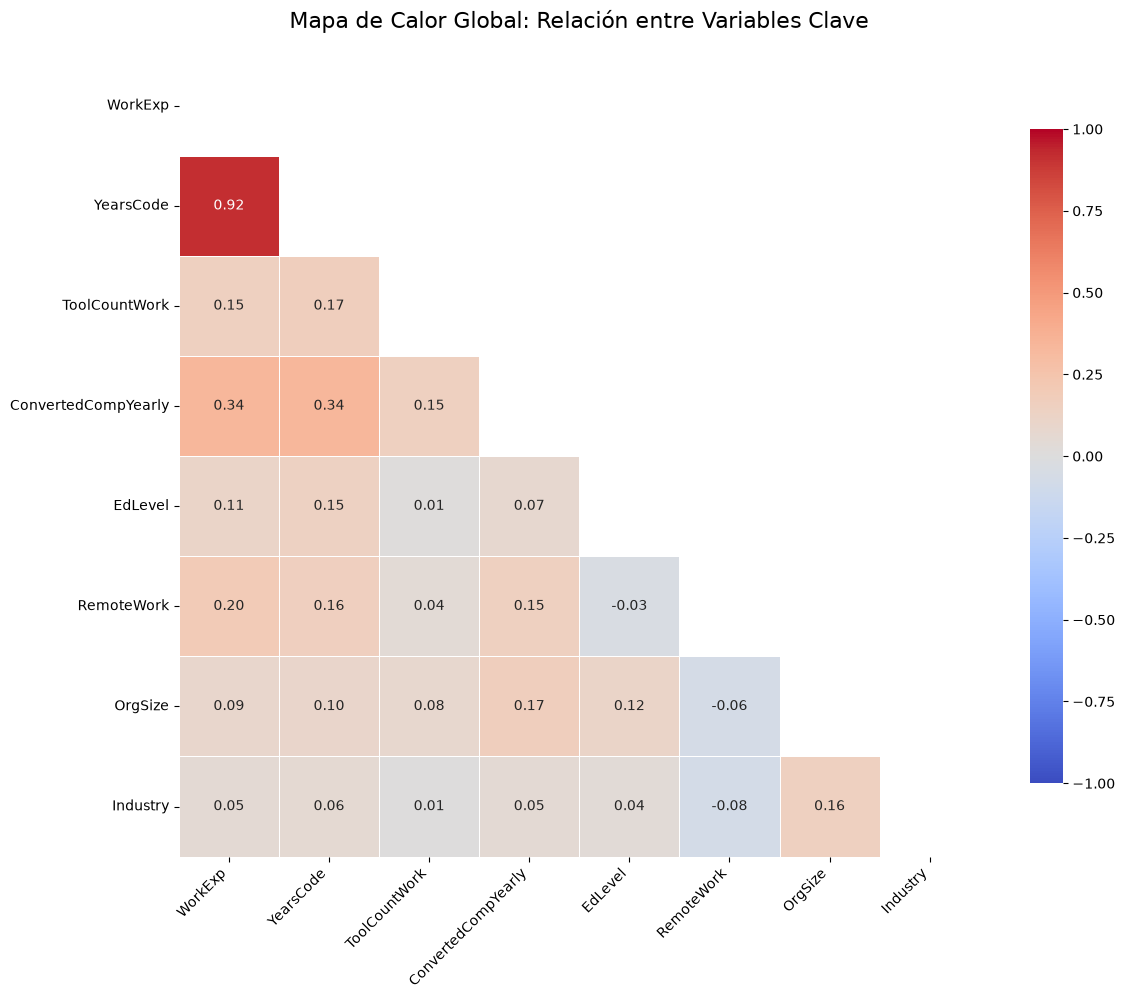

TOP 3 CORRELACIONES MÁS FUERTES:
- YearsCode & WorkExp: 0.92
- WorkExp & ConvertedCompYearly: 0.34
- ConvertedCompYearly & YearsCode: 0.34


In [26]:
cols_correlacion = [
    'WorkExp', 'YearsCode', 'ToolCountWork', 'ConvertedCompYearly',
    'EdLevel', 'RemoteWork', 'OrgSize', 'Industry'
]

cols_correlacion = [col for col in cols_correlacion if col in df_clean.columns]
corr_matrix = df_clean[cols_correlacion].corr(method='spearman')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .8}
)

plt.title('Mapa de Calor Global: Relación entre Variables Clave', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print("TOP 3 CORRELACIONES MÁS FUERTES:")
correlaciones_planas = corr_matrix.unstack().sort_values(ascending=False).drop_duplicates()
top_correlaciones = correlaciones_planas[correlaciones_planas < 1.0].head(3)
for vars_corr, valor in top_correlaciones.items():
    print(f"- {vars_corr[0]} & {vars_corr[1]}: {valor:.2f}")

### 1.26 Exportación del detaset limpio

Finalizada la limpieza, confirmada la distribución de la muestra con el EDA y validada la independencia de nuestras variables, exportamos nuestro *dataset* ya inmaculado a un archivo `survey_cleaned_eda.csv`. 
Esta matriz de talento será la "materia prima" pura que ingerirá nuestra **Libreta 2**, donde aplicaremos la ingeniería de variables y la binarización de tecnologías para preparar los tensores que alimentarán al modelo NetSTAFF.

In [27]:
df_clean.to_csv(config.PROCESSED_EDA_PATH, index=True, index_label='CandidateId')
print(f"Datos limpios guardados en: {config.PROCESSED_EDA_PATH}")
print(f"Dimensiones finales del dataset: {df_clean.shape}")

Datos limpios guardados en: /run/media/miguel-angel/Datos compartidos/TFM/data/processed/survey_cleaned_eda_hard.csv
Dimensiones finales del dataset: (33880, 33)
